# 4 · The ceiling of choosing a motion

Notebook 3's tile search finds one motion per tile and nothing learns; every network
trained here so far hedged and blurred. The way to combine the two that is left is to let
the search *propose* a few motions and a small network *pick* one per pixel - a choice,
which cannot be averaged into a blur. Before anything is trained, this notebook measures
what such a picker could gain at best:

- **the candidates**: repeat, the published search's tile motion, the same search per 64 and
  32 px block, and the next-best local minima of the tile's cost - all fixed, as cheap as the
  search;
- **the oracle**: per cell, the candidate closest to the true N+1 - the most any picker over
  those candidates can get. Per pixel it also picks noise, so cells of 4, 8 and 16 px are
  scored too: a picker at a quarter of the resolution decides per 4x4;
- **a picker that needs no training**: per cell, the candidate whose motion best explains
  N-2 -> N, the two frames the client has. How much of the oracle that already gets is
  what is left for a network.

And all of it on **whole frames**: the 113 validation clips rebuilt from the manifest and
cut into the client's 328x188 tiles (`helpers/clips.py`), beside the 80 px samples every
notebook so far was scored on. One motion per tile has not been measured on a tile before.

Steps:

1. **Data** - the samples, and the whole frames rebuilt and cut into tiles.
2. **Static methods on whole frames** - the search per tile and per block, against the samples.
3. **The oracle** - by candidate set and cell size.
4. **A picker without training** - by matching N-2 -> N.
5. **By kind**, and what it looks like.

Nothing is trained. Needs: `00_data_preprocess.ipynb` and the sources it read.
Results: `summary.md`, "The ceiling of choosing".

**How each works, and whether it learns.** Every picture here is `current` warped by a
motion, as in notebook 3; what differs is which motion, and what chooses it:

| | the motion | chosen by | learns? |
| --- | --- | --- | --- |
| repeat | none | - | no |
| tile (published) | the tile search's one motion | the search's softmax over 81 costs | no |
| block 64, block 32 | the same costs, averaged per block | each block's own softmax | no |
| minimum 2, 3 | the tile cost's next-cheapest local minima: a second and a third motion | - | no |
| oracle | one candidate per cell | the true N+1: the closest one | not a model - it reads the answer |
| match | one candidate per cell | how well it carries N-2 onto N | no |
| a learned picker | one candidate per cell | a small network | it would; it is not built - this notebook says what it could earn |

In [1]:
"""Settings."""

import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from helpers import clips, metrics, models, runs, training
from helpers.training import DATA_DIR, DEVICE

RADIUS, SCALE, SHARPNESS, STRIDE, STILL = 4, 2, 10.0, 2, 0.1   # notebook 3's published search
BLOCKS = (64, 32)        # the same search once per block of this many stream pixels
MINIMA = 2               # more motions from the tile's cost: its next-cheapest local minima
CELLS = (1, 4, 8, 16, None)   # how finely the oracle chooses, in pixels; None = once per tile
HALO = 8                 # the 80 px samples, as notebooks 2 and 3
EVERY = 2                # whole frames: every 2nd received frame N of a clip (N = 2, 6, 10, ...)
BATCH_SIZE = 32
SEED = 0
training.seed_everything(SEED)

## 1. Data

The 80 px samples as notebooks 2 and 3 score them, and the whole frames: every validation
source's clip made again from the manifest (`clips.rebuild`), cut into the client's tiles
(`clips.plan`, desktop-streamer's `planTiles`) at every second received frame. A tile is
scored on the region the client keeps from it; at a frame's edge that region sits at the
window's edge, with no halo on that side, as in the client. 640x360 stream frames are four
tiles, the 960x540 videos nine.

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
STEP = runs.received_every(manifest)
FRACTION = 1 / STEP                     # the search carries half the motion it finds

inputs, targets = runs.load(DATA_DIR, "val", manifest, halo=HALO)
masks = runs.groups(manifest, "val", inputs[:, -1], targets, HALO)
masks["pointer"] = masks.pop("cursor")   # the runs cut around the pointer
core = manifest["core"]
samples = (inputs, targets, masks, np.tile([HALO, HALO, core, core], (len(inputs), 1)))

started = time.time()
tiles = clips.load(manifest, "val", every=EVERY)
tile_masks = clips.groups(manifest, "val", tiles)
frames = (tiles["inputs"], tiles["targets"], tile_masks, tiles["boxes"])
print(f"whole frames: {len(tiles['inputs'])} tiles of {tiles['inputs'].shape[2:4]} from "
      f"{len(set(tiles['source']))} clips in {time.time() - started:.0f}s, "
      f"{tiles['inputs'].nbytes / 1e9:.1f} GB; left out (smaller than a tile): {tiles['skipped']}")

KINDS = ["page", "desktop", "photo", "video", "pointer"]
for group in (masks, tile_masks):
    for kind in KINDS:
        group[f"{kind}, changed"] = group[kind] & group["changed"]
for name, group in (("samples", masks), ("tiles", tile_masks)):
    print(f"{name:8} {group['all'].sum():5} all, {group['changed'].sum():5} changed: "
          + ", ".join(f"{kind} {group[f'{kind}, changed'].sum()}" for kind in KINDS))

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)


whole frames: 6700 tiles of (188, 328) from 113 clips in 55s, 2.5 GB; left out (smaller than a tile): []
samples   1677 all,   749 changed: page 350, desktop 52, photo 248, video 99, pointer 43
tiles     6700 all,  2480 changed: page 1135, desktop 264, photo 846, video 235, pointer 432


In [3]:
"""The clips are the ones the runs were cut from: each source's stored runs, cut again. x264
does not give the same frames twice - at a low bitrate two encodes of one clip differ by a few
luma levels - so a rebuilt clip is held to that, not to zero."""

stored = np.load(DATA_DIR / manifest["splits"]["val"]["frames"], mmap_mode="r")
size, length = manifest["input"], manifest["frames_per_run"]
for source in manifest["splits"]["val"]["sources"][::25]:
    stream, again = (clips.rebuild(source, manifest).astype(np.float32) for _ in range(2))
    first = source["runs"][0]
    difference = np.mean([np.abs(stream[source["offset"]:source["offset"] + length, y:y + size, x:x + size]
                                 - stored[first + i]).mean()
                          for i, (y, x, _) in enumerate(source["spots"])])
    codec = np.abs(stream - again).mean()
    print(f"{source['kind']:8} {source['file']:28} {difference:5.2f} levels from the stored runs, "
          f"two encodes {codec:.2f} apart (bpp {source['degradation']['bpp'] or 0:.2f})")
    assert difference < 1.5 * codec + 1, "the rebuilt clip is not the one the runs were cut from"

page     test/00000.png                0.78 levels from the stored runs, two encodes 0.43 apart (bpp 0.21)


page     test/00025.png                0.01 levels from the stored runs, two encodes 0.00 apart (bpp 0.73)


page     test/00051.png                4.78 levels from the stored runs, two encodes 3.35 apart (bpp 0.23)


desktop  test/00077.png                0.00 levels from the stored runs, two encodes 0.00 apart (bpp 0.00)


photo    DIV2K_valid_HR/0859.png       0.77 levels from the stored runs, two encodes 0.53 apart (bpp 0.79)


## 2. Static methods on whole frames

The published search finds one motion for the whole tile. The same costs averaged per
block instead of per tile (`TileSearch.blocks`) give one motion per block - right where a
tile holds two motions, but each block has fewer pixels to match, so more false matches:
notebook 1's exact per-block shift lost to the per-tile one on the 80 px samples.

And a reach of ±16 px instead of ±8: a third of the page frames that scroll move more than
8 stream pixels between received frames (the scenes record it), and a 96 px run could not
show a motion much past its halo of 16.

In [4]:
search = models.TileSearch(RADIUS, SCALE, SHARPNESS, STRIDE, FRACTION, still=STILL).to(DEVICE).eval()


def per_block(block):
    return lambda previous, current: models.warp(current, search.blocks(previous, current, block))


static = {"repeat": models.Repeat(), "linear (mock)": models.Blend(1.0),
          "tile search (published)": models.Motion(search=search, learned=False),
          "tile search ±16 px": models.Motion(search=models.TileSearch(2 * RADIUS, SCALE, SHARPNESS, STRIDE, FRACTION,
                                                                        still=STILL), learned=False),
          **{f"block {block} search": per_block(block) for block in BLOCKS}}
results = {"samples": {}, "tiles": {}}
for name, model in static.items():
    for data, (x, y, m, boxes) in (("samples", samples), ("tiles", frames)):
        results[data][name] = clips.evaluate(model, x, y, m, boxes, BATCH_SIZE)


def show(names, columns=(("samples", "changed"), ("tiles", "changed"), ("tiles", "all"))):
    print(f"{'wPSNR (dB), vs repeat':<32}" + "".join(f"{f'{d} {g}':>24}" for d, g in columns))
    for name in names:
        row = ""
        for data, group in columns:
            score = results[data][name][group]["wpsnr"]
            row += f"{score:15.2f} ({score - results[data]['repeat'][group]['wpsnr']:+6.2f})"
        print(f"{name:<32}{row}")


show(static)

wPSNR (dB), vs repeat                    samples changed           tiles changed               tiles all
repeat                                    25.69 ( +0.00)          27.09 ( +0.00)          62.84 ( +0.00)
linear (mock)                             21.94 ( -3.75)          23.22 ( -3.86)          56.99 ( -5.84)
tile search (published)                   36.78 (+11.09)          32.84 ( +5.75)          64.47 ( +1.64)
tile search ±16 px                        36.00 (+10.31)          32.80 ( +5.71)          64.45 ( +1.61)
block 64 search                           36.78 (+11.09)          32.41 ( +5.32)          63.90 ( +1.06)
block 32 search                           35.49 ( +9.80)          31.46 ( +4.37)          63.08 ( +0.25)


## 3. The oracle

Every candidate is a motion field, and `current` warped by it (`models.warp`) is its
picture. The oracle takes, per cell, the picture with the least error against the true N+1
- the error the score weighs, Y'CbCr 6:1:1 - so it is the best any picker over those
candidates can do, and it is not a model: it sees the answer. Three sets of candidates:

- **repeat | tile**: the gate, per cell instead of per tile;
- **+ blocks**: the per-block motions of 64 and 32 px beside them;
- **+ minima**: and the tile cost's next two local minima - a second and a third motion of
  the whole tile, for a scroll beside a still panel or a window dragged over a desktop.

In [5]:
SIZE = 2 * RADIUS + 1
YUV_WEIGHTS = torch.tensor(metrics.WEIGHTS, device=DEVICE).view(1, 1, 3, 1, 1)


def minima(cost, count):
    """(N, count): each tile's next-cheapest local minima of its (N, offsets) costs, after the
    cheapest - repeated when there are fewer."""
    grid = cost.view(-1, 1, SIZE, SIZE)
    lowest = -F.max_pool2d(-grid, 3, stride=1, padding=1)
    ranked = torch.where(grid == lowest, grid, torch.inf).flatten(1).argsort(dim=1)
    found = (grid == lowest).flatten(1).sum(1, keepdim=True)
    picks = torch.arange(1, count + 1, device=cost.device).expand(len(cost), -1)
    return ranked.gather(1, torch.minimum(picks, found - 1))


def candidates(previous, current, names):
    """{name: (N, 2, H, W)} the (x, y) offset every pixel of N+1 is read from in N."""
    height, width = current.shape[-2:]
    found = {"repeat": current[:, :2] * 0, "tile": search(previous, current).expand(-1, -1, height, width)}
    for block in BLOCKS:
        found[f"block {block}"] = search.blocks(previous, current, block)
    order = minima(search.costs(previous, current), MINIMA)
    for i in range(MINIMA):
        found[f"minimum {i + 2}"] = search.table[order[:, i]][:, :, None, None].expand(-1, -1, height, width)
    return [found[name] for name in names]


def error(pictures, target):
    """(N, K, H, W): the weighted squared Y'CbCr error of each of K (N, K, 3, H, W) pictures."""
    yuv = metrics.rgb_to_yuv(pictures.flatten(0, 1)).view_as(pictures)
    return ((yuv - metrics.rgb_to_yuv(target)[:, None]) ** 2 * YUV_WEIGHTS).sum(2)


def pick(pictures, errors, cell):
    """Per cell of `cell` pixels (None: the whole tile), the picture with the least error, and
    which one (N, H, W). Ties go to the first."""
    n, k, _, height, width = pictures.shape
    if cell is None:
        choice = errors.mean(dim=(2, 3)).argmin(1)[:, None, None].expand(-1, height, width)
    else:
        choice = F.avg_pool2d(errors, cell, ceil_mode=True).argmin(1)
        choice = choice.repeat_interleave(cell, 1).repeat_interleave(cell, 2)[:, :height, :width]
    index = choice[:, None, None].expand(-1, 1, 3, -1, -1)
    return pictures.gather(1, index)[:, 0], choice


class Oracle(nn.Module):
    """Per cell, the candidate closest to the target. Not a model: it sees the answer."""
    oracle = True

    def __init__(self, names, cell):
        super().__init__()
        self.names, self.cell = names, cell

    def forward(self, previous, current, target):
        pictures = torch.stack([models.warp(current, f) for f in candidates(previous, current, self.names)], 1)
        return pick(pictures, error(pictures, target), self.cell)[0]


SETS = {"repeat | tile": ["repeat", "tile"],
        "+ blocks": ["repeat", "tile", *[f"block {b}" for b in BLOCKS]],
        "+ minima": ["repeat", "tile", *[f"block {b}" for b in BLOCKS], *[f"minimum {i + 2}" for i in range(MINIMA)]]}


def cell_name(cell):
    return "per tile" if cell is None else "per pixel" if cell == 1 else f"per {cell}x{cell}"


started = time.time()
for set_name, names in SETS.items():
    for cell in CELLS:
        for data, (x, y, m, boxes) in (("samples", samples), ("tiles", frames)):
            results[data][f"oracle {set_name}, {cell_name(cell)}"] = clips.evaluate(Oracle(names, cell), x, y, m, boxes, BATCH_SIZE)
print(f"{time.time() - started:.0f}s")

for data in ("samples", "tiles"):
    base = results[data]["tile search (published)"]["changed"]["wpsnr"]
    print(f"\n{data}, changed: oracle wPSNR (dB), and over the published search ({base:.2f})")
    print(f"{'':<16}" + "".join(f"{cell_name(cell):>18}" for cell in CELLS))
    for set_name in SETS:
        row = [results[data][f"oracle {set_name}, {cell_name(cell)}"]["changed"]["wpsnr"] for cell in CELLS]
        print(f"{set_name:<16}" + "".join(f"{score:10.2f} ({score - base:+5.2f})" for score in row))

231s

samples, changed: oracle wPSNR (dB), and over the published search (36.78)
                         per pixel           per 4x4           per 8x8         per 16x16          per tile
repeat | tile        38.41 (+1.62)     37.53 (+0.75)     37.39 (+0.61)     37.29 (+0.51)     37.06 (+0.27)
+ blocks             38.89 (+2.10)     37.92 (+1.13)     37.75 (+0.97)     37.51 (+0.73)     37.19 (+0.40)
+ minima             39.95 (+3.17)     38.22 (+1.44)     37.95 (+1.17)     37.55 (+0.77)     37.30 (+0.51)

tiles, changed: oracle wPSNR (dB), and over the published search (32.84)
                         per pixel           per 4x4           per 8x8         per 16x16          per tile
repeat | tile        34.62 (+1.78)     33.80 (+0.96)     33.67 (+0.82)     33.58 (+0.74)     33.35 (+0.50)
+ blocks             35.56 (+2.72)     34.50 (+1.66)     34.29 (+1.45)     34.11 (+1.27)     33.68 (+0.84)
+ minima             36.62 (+3.77)     34.94 (+2.09)     34.61 (+1.77)     34.40 (+1.56)     33.

## 4. A picker without training

The client has N-2 and N, not N+1. A candidate's motion carried the whole way - twice the
share it is given for N+1 - should take N-2 to N where it is right, so per cell the
candidate that best explains N-2 -> N is a choice made from the two frames the client has.
It is a search over a handful of motions instead of 81, per cell instead of per tile.
What it does not reach of the oracle is what a learned picker would have to find.

In [6]:
class Match(nn.Module):
    """Per cell, the candidate whose motion carried the whole way best takes N-2 to N."""

    def __init__(self, names, cell):
        super().__init__()
        self.names, self.cell = names, cell

    def forward(self, previous, current):
        offsets = candidates(previous, current, self.names)
        pictures = torch.stack([models.warp(current, f) for f in offsets], 1)
        explained = torch.stack([models.warp(previous, f / FRACTION) for f in offsets], 1)
        return pick(pictures, error(explained, current), self.cell)[0]


for set_name in ("+ blocks", "+ minima"):
    for cell in (8, 16, 32):
        for data, (x, y, m, boxes) in (("samples", samples), ("tiles", frames)):
            results[data][f"match {set_name}, {cell_name(cell)}"] = clips.evaluate(Match(SETS[set_name], cell), x, y, m, boxes, BATCH_SIZE)
show([name for name in results["tiles"] if name.startswith("match")] + ["tile search (published)"])

wPSNR (dB), vs repeat                    samples changed           tiles changed               tiles all
match + blocks, per 8x8                   34.36 ( +8.67)          31.97 ( +4.88)          63.67 ( +0.84)
match + blocks, per 16x16                 35.99 (+10.30)          32.50 ( +5.41)          63.86 ( +1.03)
match + blocks, per 32x32                 36.27 (+10.58)          32.71 ( +5.62)          63.94 ( +1.10)
match + minima, per 8x8                   33.73 ( +8.04)          31.58 ( +4.49)          63.36 ( +0.53)
match + minima, per 16x16                 35.63 ( +9.94)          32.32 ( +5.24)          63.77 ( +0.94)
match + minima, per 32x32                 36.18 (+10.48)          32.67 ( +5.58)          63.91 ( +1.08)
tile search (published)                   36.78 (+11.09)          32.84 ( +5.75)          64.47 ( +1.64)


## 5. By kind

Changed tiles of whole frames, by kind of source and around the pointer.

In [7]:
best_oracle = "oracle + minima, per 4x4"
shown = ["repeat", "tile search (published)", *[f"block {b} search" for b in BLOCKS],
         "match + blocks, per 16x16", "oracle repeat | tile, per tile", "oracle + blocks, per 4x4", best_oracle]
for data in ("tiles", "samples"):
    print(f"\n{data}: wPSNR (dB), changed")
    print(f"{'':<32}" + "".join(f"{kind:>10}" for kind in KINDS))
    for name in shown:
        print(f"{name:<32}" + "".join(f"{results[data][name][f'{kind}, changed']['wpsnr']:10.2f}" for kind in KINDS))


tiles: wPSNR (dB), changed
                                      page   desktop     photo     video   pointer
repeat                               25.80     28.68     25.79     36.19     25.62
tile search (published)              32.42     28.66     33.50     37.23     29.31
block 64 search                      31.55     28.62     33.11     38.33     28.96
block 32 search                      29.84     28.45     32.71     38.13     28.24
match + blocks, per 16x16            31.68     28.70     33.10     38.54     29.18
oracle repeat | tile, per tile       33.33     28.72     33.67     37.45     29.94
oracle + blocks, per 4x4             34.35     29.69     34.75     39.73     31.32
oracle + minima, per 4x4             35.10     30.08     34.90     39.74     31.76

samples: wPSNR (dB), changed
                                      page   desktop     photo     video   pointer
repeat                               23.49     25.94     25.04     34.98     26.15
tile search (published)      

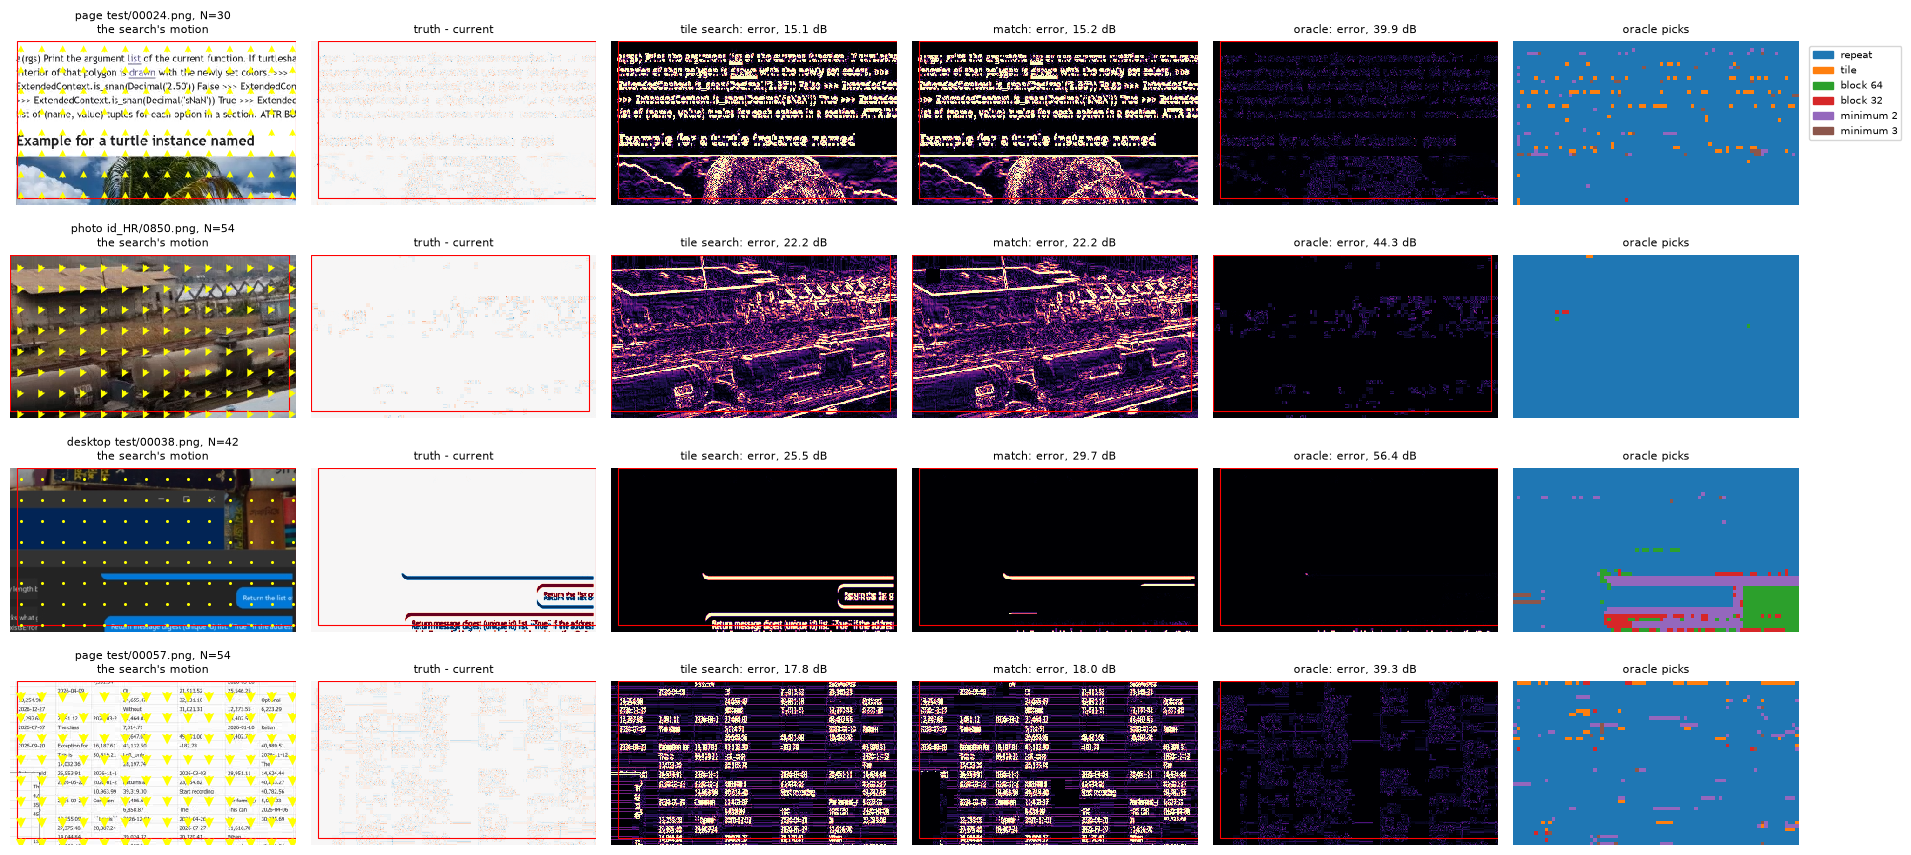

arrows four times their length; changes and errors full colour at 48 luma levels


In [8]:
"""Changed whole-frame tiles where the oracle gains most over the published search: the
motion the search carries on, what each method makes, and which candidate the oracle picks."""

from helpers import show

names = SETS["+ minima"]
oracle = Oracle(names, 4)
match = Match(SETS["+ blocks"], 16)
chosen = np.flatnonzero(tile_masks["changed"])
gains = []
with torch.no_grad():
    for first in range(0, len(chosen), BATCH_SIZE):
        index = chosen[first:first + BATCH_SIZE]
        previous, current = training.to_tensor(tiles["inputs"][index]).unbind(1)
        target = training.to_tensor(tiles["targets"][index])
        published = static["tile search (published)"](previous, current)
        gains += [metrics.wpsnr(oracle(previous[i:i + 1], current[i:i + 1], target[i:i + 1]), target[i:i + 1])
                  - metrics.wpsnr(published[i:i + 1], target[i:i + 1]) for i in range(len(index))]
rng = np.random.default_rng(SEED)
top = chosen[np.argsort(gains)[::-1][:40]]
picks = rng.choice(top, 4, replace=False)

columns = ["current, the search's motion", "truth - current", "tile search: error", "match: error", "oracle: error",
           "oracle picks"]
fig, axes = plt.subplots(len(picks), len(columns), figsize=(3.2 * len(columns), 2.2 * len(picks)), squeeze=False)
for row, index in enumerate(picks):
    previous, current = training.to_tensor(tiles["inputs"][index:index + 1]).unbind(1)
    target = training.to_tensor(tiles["targets"][index:index + 1])
    with torch.no_grad():
        pictures = torch.stack([models.warp(current, f) for f in candidates(previous, current, names)], 1)
        best, choice = pick(pictures, error(pictures, target), 4)
        made = {"tile search": static["tile search (published)"](previous, current), "match": match(previous, current),
                "oracle": best}
        field = search(previous, current).expand(-1, -1, *current.shape[-2:])
    box = tiles["boxes"][index]
    source = manifest["splits"]["val"]["sources"][tiles["source"][index]]
    ax = axes[row]
    show.motion(ax[0], current, field, f"{source['kind']} {source['file'][-14:]}, N={tiles['frame'][index]}\n"
                f"the search's motion", box, every=24, gain=4)
    show.change(ax[1], current, target, columns[1], box)
    for column, name in enumerate(made, start=2):
        score = metrics.wpsnr(clips.kept(made[name], box), clips.kept(target, box))
        show.error(ax[column], made[name], target, f"{name}: error, {score:.1f} dB", box)
    ax[5].imshow(choice[0].cpu().numpy(), cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
    ax[5].set_title(columns[5], fontsize=8)
    ax[5].axis("off")
show.legend(axes[0][5], names, loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=7)
fig.tight_layout()
plt.show()
print(f"arrows four times their length; changes and errors full colour at {show.LEVELS} luma levels")


### Stop or go, over a whole clip

The tiles above are mostly one case: a scroll that stopped. Here is one page clip scrolled by
the wheel, every generated frame of it: on top the scroll as the scene recorded it - the
received frames, and at every frame between them, repeat and the motion carried on (the
search's rule); below, the whole frame's wPSNR of repeat, the published search, and the
oracle that only chooses between the two per tile. Where the scroll runs, the search is far
above repeat; at the frame a notch stops, it falls under it, and the oracle shows what
knowing *when* would be worth. Frames where nothing moved are near perfect for all three
and capped at 60 dB.

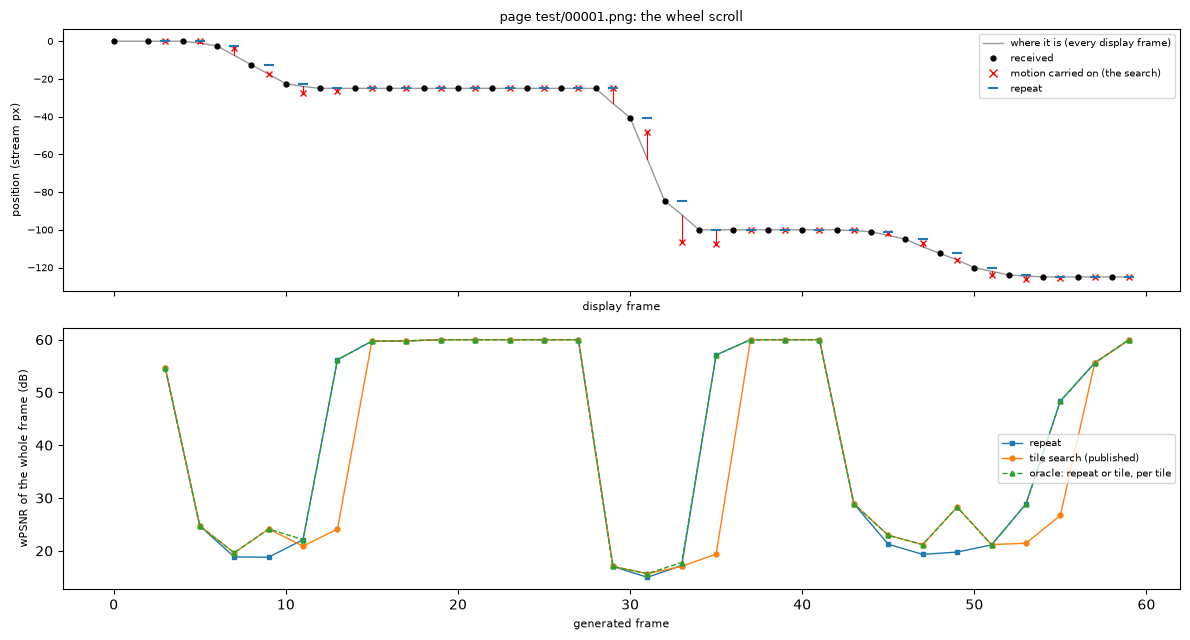

In [9]:
"""One clip scrolled by the wheel, every generated frame of it."""

source = next(s for s in manifest["splits"]["val"]["sources"] if (s.get("scene") or {}).get("background") == "wheel")
stream = clips.rebuild(source, manifest)
height, width = stream.shape[1:3]
layout, size = clips.plan(width, height)


def whole(made):
    """A frame put together from its tiles, each giving the region the client keeps."""
    frame = torch.zeros(3, height, width, device=DEVICE)
    for tile, (ix, iy, ox, oy, w, h) in zip(made, layout):
        frame[:, iy + oy:iy + oy + h, ix + ox:ix + ox + w] = tile[:, oy:oy + h, ox:ox + w]
    return frame[None]


gate_oracle = Oracle(SETS["repeat | tile"], None)
made_frames, scores = [], {"repeat": [], "tile search (published)": [], "oracle: repeat or tile, per tile": []}
with torch.no_grad():
    for n in range(STEP, len(stream) - 1, STEP):
        windows = np.stack([stream[[n - STEP, n, n + 1], iy:iy + size[0], ix:ix + size[1]] for ix, iy, *_ in layout])
        previous, current, target = training.to_tensor(windows).unbind(1)
        made = {"repeat": current, "tile search (published)": static["tile search (published)"](previous, current),
                "oracle: repeat or tile, per tile": gate_oracle(previous, current, target)}
        for name, frame in made.items():
            scores[name].append(min(60.0, metrics.wpsnr(whole(frame), whole(target))))
        made_frames.append(n + 1)

scroll = np.array(source["scene"]["scroll"]) / manifest["scale"]
axis = int(np.abs(scroll[-1] - scroll[0]).argmax())
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
show.track(top, scroll[:, axis], STEP, FRACTION, f"{source['kind']} {source['file']}: the wheel scroll")
top.legend(fontsize=7)
for (name, values), style in zip(scores.items(), ("s-", "o-", "^--")):
    bottom.plot(made_frames, values, style, ms=3.5, lw=1, label=name)
bottom.set_ylabel("wPSNR of the whole frame (dB)", fontsize=8)
bottom.set_xlabel("generated frame", fontsize=8)
bottom.legend(fontsize=7)
fig.tight_layout()
plt.show()

## What it says

- **On whole frames the search gains half as much.** +5.8 dB over repeat on the changed
  tiles, against +11.1 on the 80 px samples, and nothing on desktops (28.66 against 28.68):
  a 320x180 region counts as changed for a dragged window or a menu that moves a corner of
  it, and one motion for the tile cannot move that corner without the rest. Pages lose most
  (32.4 against 37.5 on samples).
- **Reaching further does not help.** ±16 px scores as ±8 px: a scroll that fast is a wheel
  notch easing in or out, and half its motion from N-2 to N is not its motion to N+1.
  Smaller blocks lose too: 64 px blocks -0.4 dB, 32 px -1.4 - the false matches notebook 1
  found.
- **The ceiling of choosing is about 1.5-2 dB.** Per 4x4 to 16x16 cell, the best of the six
  candidates is +1.6 to +2.1 dB over the published search on changed whole-frame tiles, most
  of it on pages and around the pointer; choosing only repeat or the tile per tile is +0.5.
  Per pixel it is +3.8, but that picks noise too. It is an upper bound a picker cannot reach:
  it sees N+1.
- **Two kinds of choice make that ceiling.** Whether a motion goes on: the tiles the oracle
  gains most on are pages where a wheel notch ended between N and N+1 - the search carries it
  on (18 dB) and the oracle repeats (40) - and choosing only repeat or the tile, per tile, is
  +0.5 of it. And where each motion is: a window dragged or a region scrolled over a still
  desktop, where it takes the per-block motions for the part that moves.
- **The two frames do not tell which candidate is right.** Choosing per cell by how well a
  candidate takes N-2 to N loses to the published search at every cell size (-0.1 to -0.9
  dB): within a cell the matches are as ambiguous as per pixel. A learned picker would have
  to find in a wider context what this one cannot - and every network so far has not.

So a learned picker over these candidates could gain at most +1.5-2 dB on changed tiles, a
third of what the search itself gains, and a realistic one less. The candidates are not the
limit - the oracle with them all is well above the search - the evidence for choosing is.